# YOLOv5 Custom Training — FaceDetector (GitHub or Roboflow)

**Google Colab notebook (English edition)** · Based on the workflow of [YOLOv5 Custom Training](https://colab.research.google.com/github/serivan/DeepLearning/blob/master/homeworks/YOLOv5_Custom_Training.ipynb).

This notebook demonstrates the complete object-detection pipeline: **environment setup → dataset download → dataset configuration → label inspection → YOLOv5 training → evaluation → inference → weight export**.

Choose **one** dataset source:

- **GitHub**: the dataset already stored under [`serivan/DeepLearning/Datasets/Yolo`](https://github.com/serivan/DeepLearning/tree/master/Datasets/Yolo).
- **Roboflow**: download the original [FaceDetector dataset](https://universe.roboflow.com/ero/facedetector-mc4s6-10anv/dataset/1) as a **YOLOv5 PyTorch** export.

For best performance, select **Runtime → Change runtime type → GPU** in Colab before running the cells. Run the cells from top to bottom.

## 1. Choose the dataset source and training parameters

Set `DATA_SOURCE` to `"github"` or `"roboflow"`. The Roboflow project parameters below are prefilled for this FaceDetector dataset. For a different dataset, adjust the project, version and class information provided by Roboflow; the notebook reads class names from its exported YAML.

In [36]:
DATA_SOURCE = "github"   # Choose "github" OR "roboflow"

# Roboflow dataset identifiers (used only if DATA_SOURCE == "roboflow")
ROBOFLOW_WORKSPACE = "ero"
ROBOFLOW_PROJECT = "facedetector-mc4s6-10anv"
ROBOFLOW_VERSION = 1

# YOLOv5 training configuration
MODEL_WEIGHTS = "yolov5s.pt"  # Pretrained YOLOv5 small model
EPOCHS = 50
BATCH_SIZE = 16              # Reduce to 8 or 4 if Colab reports CUDA out of memory
IMAGE_SIZE = 640
RUN_NAME = "face_detector"

assert DATA_SOURCE in {"github", "roboflow"}, "Choose github or roboflow"

## 2. Prepare the Colab environment and install YOLOv5

Clone the official YOLOv5 repository, install its requirements, and check whether a GPU is available. Internet access is needed inside Colab for GitHub/Roboflow and pretrained weights.

In [37]:
from pathlib import Path
import os, sys, subprocess

YOLO_DIR = Path("/content/yolov5")
if not YOLO_DIR.exists():
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/ultralytics/yolov5.git", str(YOLO_DIR)], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(YOLO_DIR / "requirements.txt")], check=True)
if DATA_SOURCE == "roboflow":
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "roboflow"], check=True)

import torch
print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: Training on CPU can be very slow. Enable GPU in Colab Runtime settings.")

PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


## 3. Download the dataset (GitHub **or** Roboflow)

### Option A — GitHub (no API key)

The notebook clones [`serivan/DeepLearning`](https://github.com/serivan/DeepLearning) and uses the already-uploaded dataset in `Datasets/Yolo`.

### Option B — Roboflow (API key required)

1. Sign into [Roboflow](https://app.roboflow.com/), open your workspace and locate the dataset version.
2. Open **Download Dataset** / **Export Dataset**, and choose **YOLOv5 PyTorch**. If Roboflow displays a Python snippet, it corresponds to `version.download("yolov5pytorch")` below.
3. Obtain a Roboflow API key from your account settings. You can save it in **Colab → Secrets** as `ROBOFLOW_API_KEY`, or enter it when prompted; **do not put API keys into the notebook or GitHub**.
4. Select `DATA_SOURCE = "roboflow"` in section 1, then execute this cell.

**Note:** Roboflow project access and export availability depend on your account and the dataset's permissions. If your Roboflow export is private, make sure your API key has access.

In [38]:
from pathlib import Path

if DATA_SOURCE == "github":
    REPO_DIR = Path("/content/DeepLearning")
    if not REPO_DIR.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/serivan/DeepLearning.git", str(REPO_DIR)], check=True)
    DATASET_DIR = REPO_DIR / "Datasets" / "Yolo"
else:
    from roboflow import Roboflow
    from getpass import getpass
    try:
        from google.colab import userdata
        api_key = userdata.get("ROBOFLOW_API_KEY")
    except Exception:
        api_key = None
    if not api_key:
        api_key = getpass("Enter your Roboflow API key (hidden): ")
    if not api_key:
        raise ValueError("A Roboflow API key is required for this source")
    rf = Roboflow(api_key=api_key)
    project = rf.workspace(ROBOFLOW_WORKSPACE).project(ROBOFLOW_PROJECT)
    version = project.version(ROBOFLOW_VERSION)
    dataset = version.download("yolov5pytorch", location="/content/roboflow_dataset")
    DATASET_DIR = Path(dataset.location).resolve()
    del api_key  # Avoid retaining a plaintext local reference longer than needed

DATASET_DIR = DATASET_DIR.resolve()
print("Dataset source:", DATA_SOURCE)
print("Dataset location:", DATASET_DIR)
assert DATASET_DIR.is_dir(), f"Dataset directory not found: {DATASET_DIR}"

Dataset source: github
Dataset location: /content/DeepLearning/Datasets/Yolo


## 4. Validate the dataset and build a Colab-compatible `data.yaml`

YOLOv5 needs paths to training and validation **image directories** plus the matching label files in sibling `labels` directories. A common Roboflow dataset layout is `train/images`, `valid/images`, `test/images`.

The GitHub dataset's original YAML uses relative paths that can be ambiguous after copying. The cell below writes a new, **absolute-path** configuration under `/content/yolov5/face_dataset.yaml`. It also handles datasets that call their validation split `val` instead of `valid`. If no test split exists, evaluation on the test set will be skipped.

In [39]:
import yaml

source_yaml = DATASET_DIR / "data.yaml"
assert source_yaml.exists(), f"Missing data.yaml: {source_yaml}"
with open(source_yaml, "r", encoding="utf-8") as f:
    original_config = yaml.safe_load(f)

# Prefer the conventional train/valid/test layout and allow val/ as an alternative.
def image_dir_for(split_names):
    for name in split_names:
        candidate = DATASET_DIR / name / "images"
        if candidate.is_dir():
            return candidate
    return None

train_images = image_dir_for(["train"])
valid_images = image_dir_for(["valid", "val"])
test_images  = image_dir_for(["test"])
assert train_images is not None, "Missing train/images"
assert valid_images is not None, "Missing valid/images or val/images"

names = original_config.get("names")
if isinstance(names, dict):
    names = [value for _, value in sorted(names.items(), key=lambda item: int(item[0]))]
assert names, "Class names not found in the exported data.yaml"
num_classes = len(names)
if "nc" in original_config:
    assert int(original_config["nc"]) == num_classes, "nc does not match names in data.yaml"

config = {
    "path": str(DATASET_DIR),
    "train": str(train_images),
    "val": str(valid_images),
    "nc": num_classes,
    "names": names,
}
if test_images is not None:
    config["test"] = str(test_images)

DATA_YAML = YOLO_DIR / "face_dataset.yaml"
with open(DATA_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print(DATA_YAML.read_text())
for label, folder in [("train", train_images), ("valid", valid_images), ("test", test_images)]:
    if folder is None:
        print(f"{label}: no split")
        continue
    labels = folder.parent / "labels"
    assert labels.is_dir(), f"Missing labels folder: {labels}"
    img_count = len([p for p in folder.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}])
    txt_count = len(list(labels.glob("*.txt")))
    print(f"{label}: {img_count} images, {txt_count} label files")
    assert img_count > 0, f"No images found in {folder}"

path: /content/DeepLearning/Datasets/Yolo
train: /content/DeepLearning/Datasets/Yolo/train/images
val: /content/DeepLearning/Datasets/Yolo/valid/images
nc: 1
names:
- face
test: /content/DeepLearning/Datasets/Yolo/test/images

train: 807 images, 807 label files
valid: 119 images, 119 label files
test: 108 images, 108 label files


In [40]:
print()

In [41]:
import yaml

source_yaml = DATASET_DIR / "data.yaml"
assert source_yaml.exists(), f"Missing data.yaml: {source_yaml}"
with open(source_yaml, "r", encoding="utf-8") as f:
    original_config = yaml.safe_load(f)

# Prefer the conventional train/valid/test layout and allow val/ as an alternative.
def image_dir_for(split_names):
    for name in split_names:
        candidate = DATASET_DIR / name / "images"
        if candidate.is_dir():
            return candidate
    return None

train_images = image_dir_for(["train"])
valid_images = image_dir_for(["valid", "val"])
test_images  = image_dir_for(["test"])
assert train_images is not None, "Missing train/images"
assert valid_images is not None, "Missing valid/images or val/images"

names = original_config.get("names")
if isinstance(names, dict):
    names = [value for _, value in sorted(names.items(), key=lambda item: int(item[0]))]
assert names, "Class names not found in the exported data.yaml"
num_classes = len(names)
if "nc" in original_config:
    assert int(original_config["nc"]) == num_classes, "nc does not match names in data.yaml"

config = {
    "path": str(DATASET_DIR),
    "train": str(train_images),
    "val": str(valid_images),
    "nc": num_classes,
    "names": names,
}
if test_images is not None:
    config["test"] = str(test_images)

DATA_YAML = YOLO_DIR / "face_dataset.yaml"
with open(DATA_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print(DATA_YAML.read_text())
for label, folder in [("train", train_images), ("valid", valid_images), ("test", test_images)]:
    if folder is None:
        print(f"{label}: no split")
        continue
    labels = folder.parent / "labels"
    assert labels.is_dir(), f"Missing labels folder: {labels}"
    img_count = len([p for p in folder.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}])
    txt_count = len(list(labels.glob("*.txt")))
    print(f"{label}: {img_count} images, {txt_count} label files")
    assert img_count > 0, f"No images found in {folder}"

path: /content/DeepLearning/Datasets/Yolo
train: /content/DeepLearning/Datasets/Yolo/train/images
val: /content/DeepLearning/Datasets/Yolo/valid/images
nc: 1
names:
- face
test: /content/DeepLearning/Datasets/Yolo/test/images

train: 807 images, 807 label files
valid: 119 images, 119 label files
test: 108 images, 108 label files


In [42]:
print(DATA_YAML)

/content/yolov5/face_dataset.yaml


## 5. Inspect a few training images and their annotations

YOLO format labels contain `class_id x_center y_center width height` (normalized to 0–1). These examples plot bounding boxes to help verify the dataset before training.

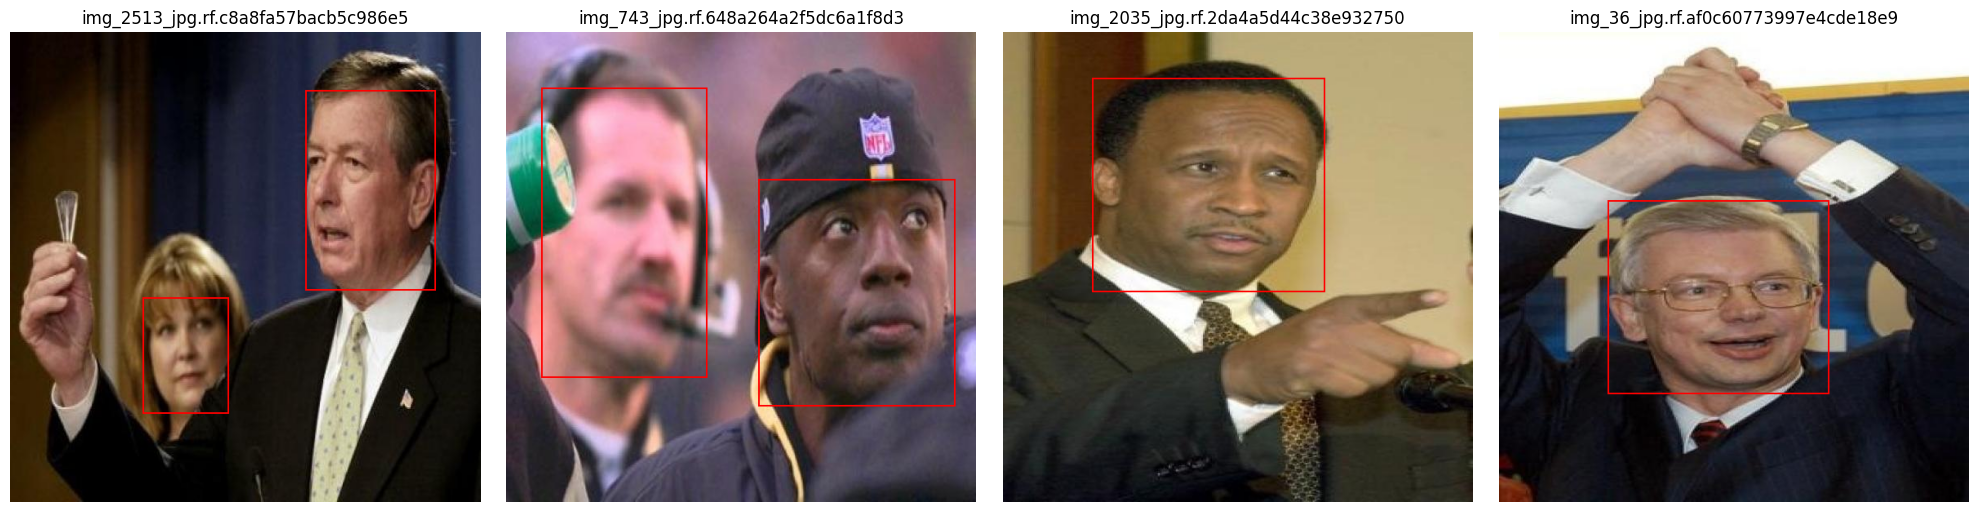

In [43]:
import random
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

image_files = [p for p in train_images.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}]
chosen = random.sample(image_files, min(4, len(image_files)))
fig, axes = plt.subplots(1, len(chosen), figsize=(5 * len(chosen), 5))
if len(chosen) == 1:
    axes = [axes]
for ax, image_path in zip(axes, chosen):
    im = Image.open(image_path).convert("RGB")
    w, h = im.size
    canvas = ImageDraw.Draw(im)
    annotation = image_path.parent.parent / "labels" / (image_path.stem + ".txt")
    if annotation.exists():
        for line in annotation.read_text().splitlines():
            parts = line.split()
            if len(parts) != 5:
                continue
            cls, cx, cy, bw, bh = map(float, parts)
            x1, y1 = (cx - bw/2)*w, (cy - bh/2)*h
            x2, y2 = (cx + bw/2)*w, (cy + bh/2)*h
            canvas.rectangle([x1, y1, x2, y2], outline="red", width=max(2, w//250))
    ax.imshow(im)
    ax.set_title(image_path.name[:35])
    ax.axis("off")
plt.tight_layout()
plt.show()

## 6. Train YOLOv5 on the selected dataset

Training starts with the pretrained `yolov5s.pt` weights (transfer learning). Use more epochs or a larger YOLOv5 variant if appropriate. The best checkpoint will be stored at `runs/train/face_detector/weights/best.pt`. On GPU-memory errors, reduce `BATCH_SIZE`.

In [44]:
import subprocess, sys
%cd /content/yolov5
#Compact command
#train_cmd = [sys.executable, "-u", "train.py", "--img", str(IMAGE_SIZE),
#             "--batch", str(BATCH_SIZE), "--epochs", str(EPOCHS),
#             "--data", str(DATA_YAML), "--weights", MODEL_WEIGHTS,
#             "--project", "runs/train", "--name", RUN_NAME, "--exist-ok"]
#subprocess.run(train_cmd, cwd=str(YOLO_DIR), check=True)


/content/yolov5


In [35]:
!python -u train.py \
    --img $IMAGE_SIZE \
    --batch $BATCH_SIZE \
    --epochs $EPOCHS \
    --data $DATA_YAML \
    --weights $MODEL_WEIGHTS \
    --name $RUN_NAME \
    --project runs/train \
    --exist-ok

WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1793200905.140908   10372 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice: (30 second timeout) 
wandb: WARNING W&B disabled due to login timeout.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin
train: weights=yolov5s.pt, cfg=, data=/content/yolov5/face_dataset.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=50, batch_size=16, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=data/hyps, resume_evolve=None, bucket=, cache=None, image_weights=False, device=, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, workers=8, proje

In [45]:
BEST_WEIGHTS = YOLO_DIR / "runs" / "train" / RUN_NAME / "weights" / "best.pt"
assert BEST_WEIGHTS.exists(), f"Training did not create {BEST_WEIGHTS}"
print("Best model:", BEST_WEIGHTS)

Best model: /content/yolov5/runs/train/face_detector/weights/best.pt


## 7. View training metrics

YOLOv5 saves training curves (loss, precision, recall and mAP) to `results.png`. Inspect these plots for signs of overfitting or insufficient training.

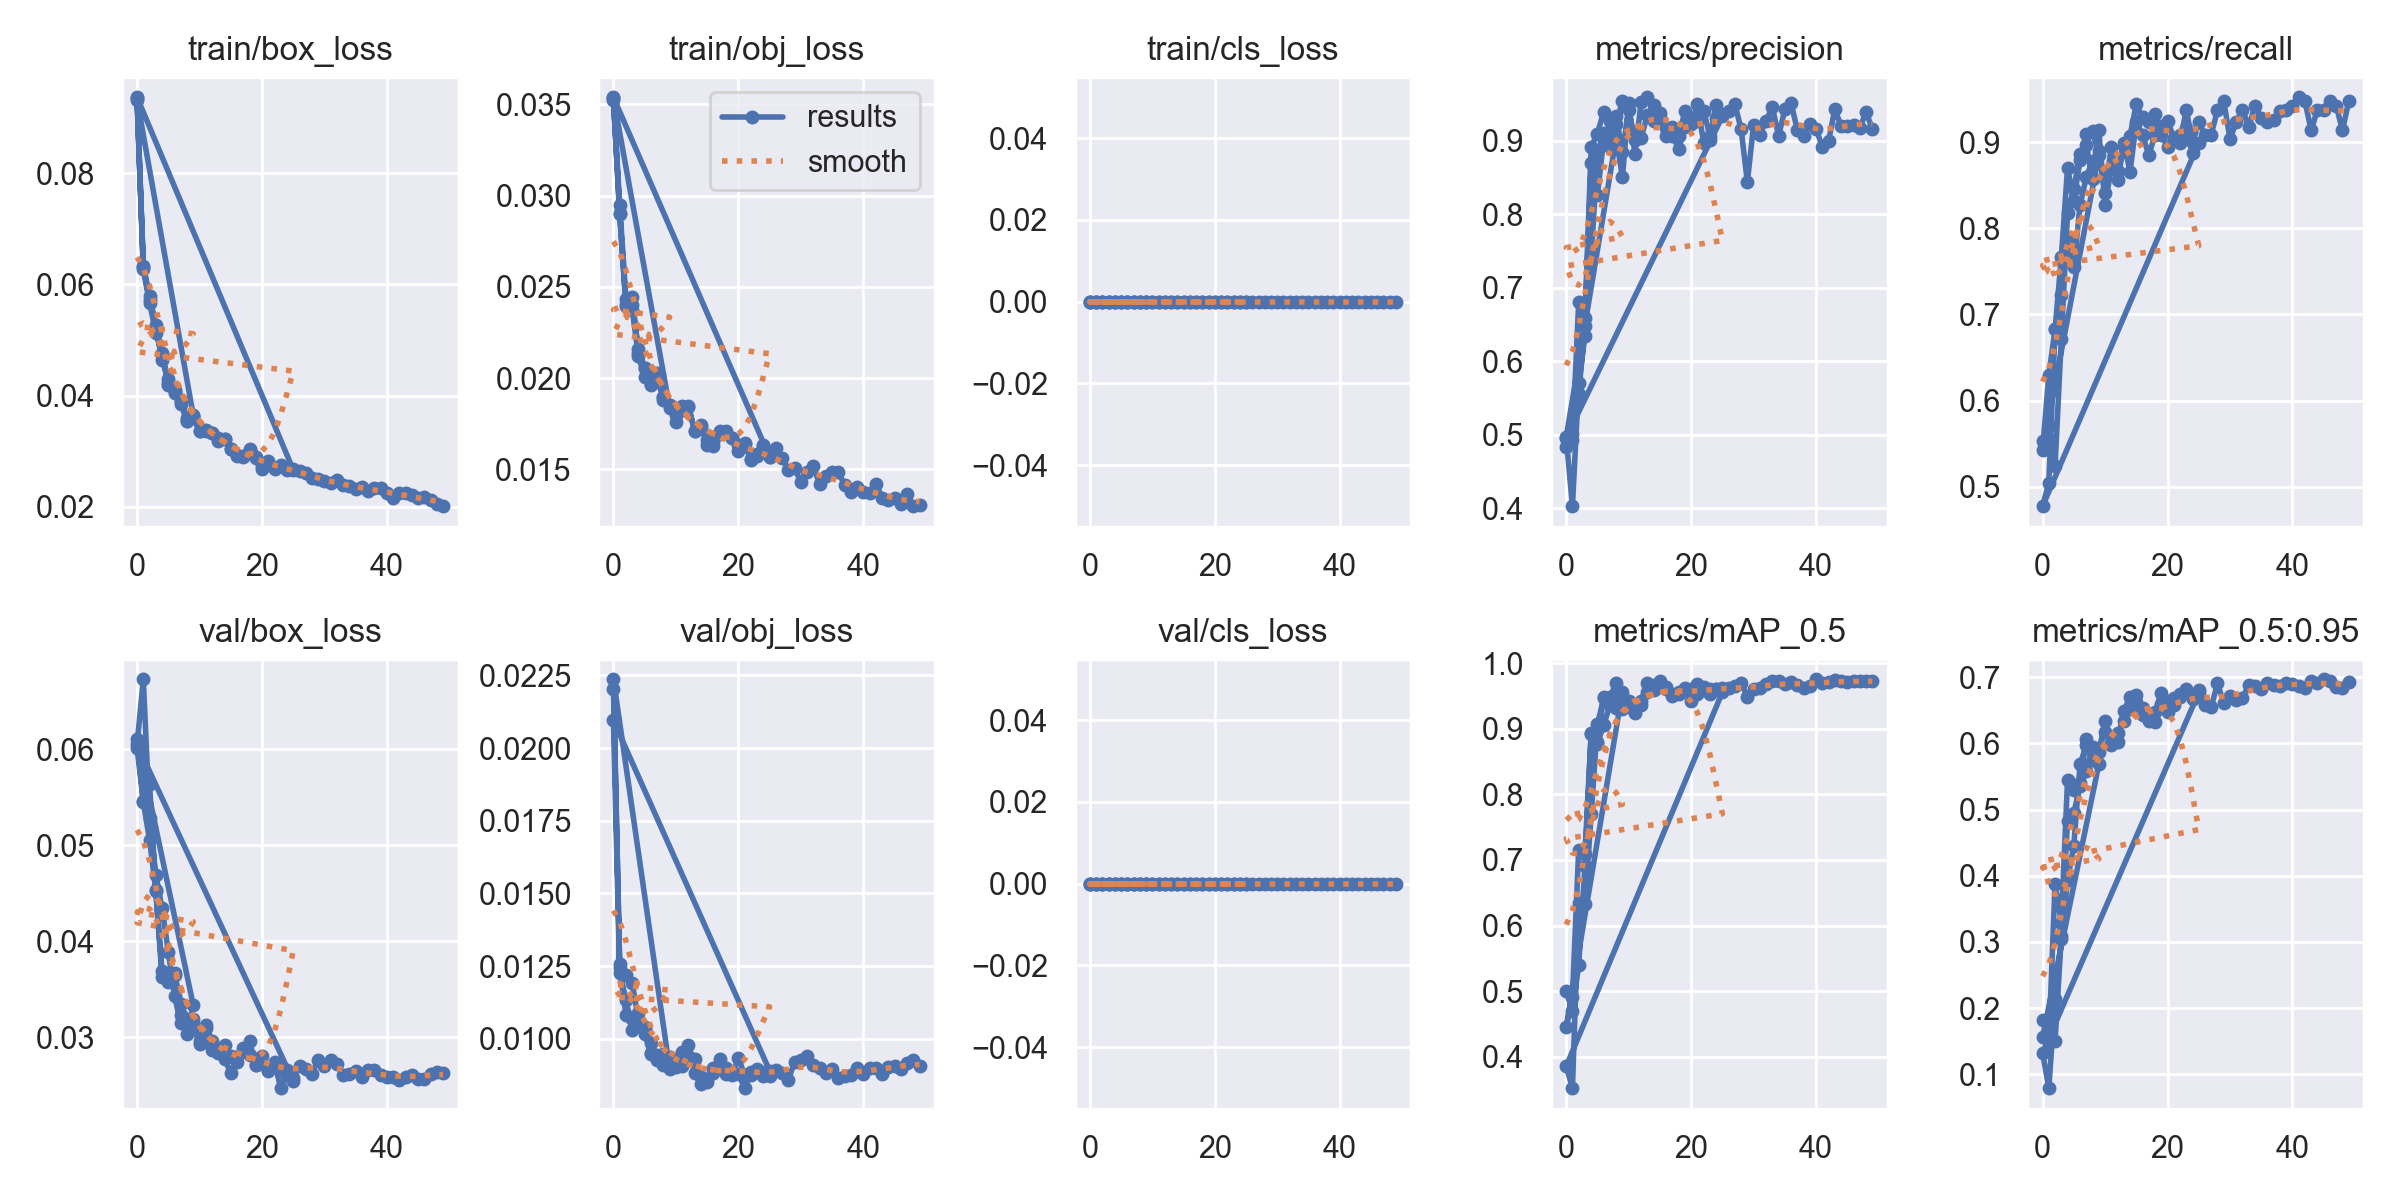

In [46]:
from IPython.display import display
from PIL import Image

results_image = YOLO_DIR / "runs" / "train" / RUN_NAME / "results.png"
if results_image.exists():
    display(Image.open(results_image))
else:
    print("Results figure was not found:", results_image)

## 8. Evaluate on the test set (if provided)

Run YOLOv5 validation using the **held-out test split**, which should not be used to tune training. Reported metrics include precision, recall and mAP. If the export has no test split, the cell will skip evaluation.

In [47]:
if test_images is not None:
    val_cmd = [sys.executable, "val.py", "--weights", str(BEST_WEIGHTS),
               "--data", str(DATA_YAML), "--task", "test", "--img", str(IMAGE_SIZE),
               "--project", "runs/val", "--name", RUN_NAME, "--exist-ok"]
    subprocess.run(val_cmd, cwd=str(YOLO_DIR), check=True)
else:
    print("No test split found. Skipping held-out test evaluation.")

## 9. Run detection on test images (or validation images)

Apply the trained model to images and inspect the predicted bounding boxes. Output images are saved under `runs/detect/face_predictions`.

img_768_jpg.rf.ef0618f6f8eac1d61732a9602abdf3b1.jpg


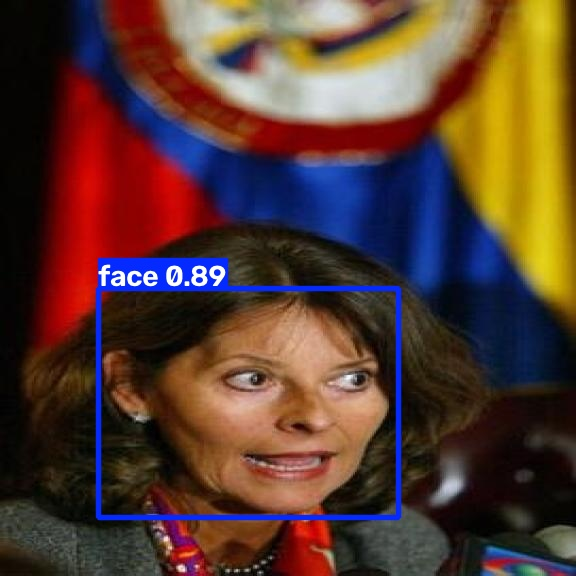

img_760_jpg.rf.eb265cc4360e6df3b6373b689955aef1.jpg


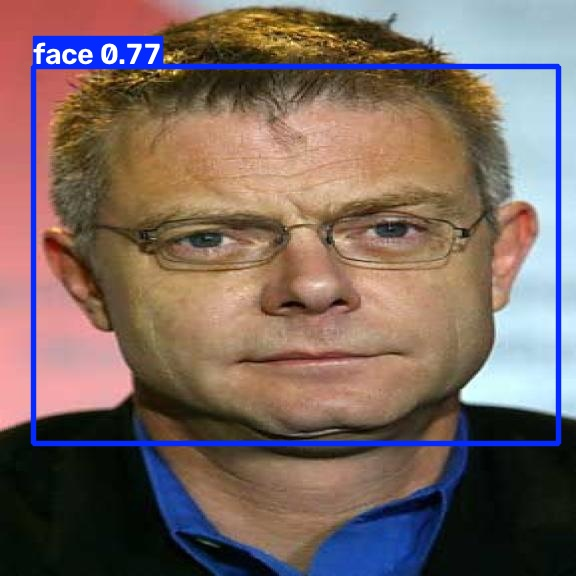

img_357_jpg.rf.a4c530cd0a2b810d6c222921978591c3.jpg


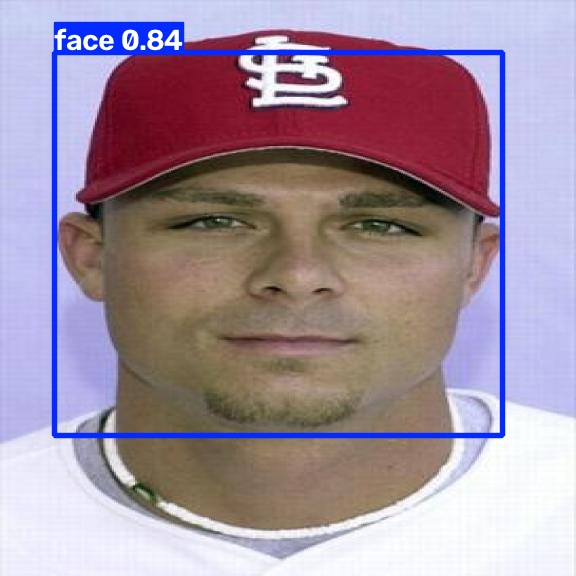

img_859_jpg.rf.711ce33d988316f929e8c4e57e3407dd.jpg


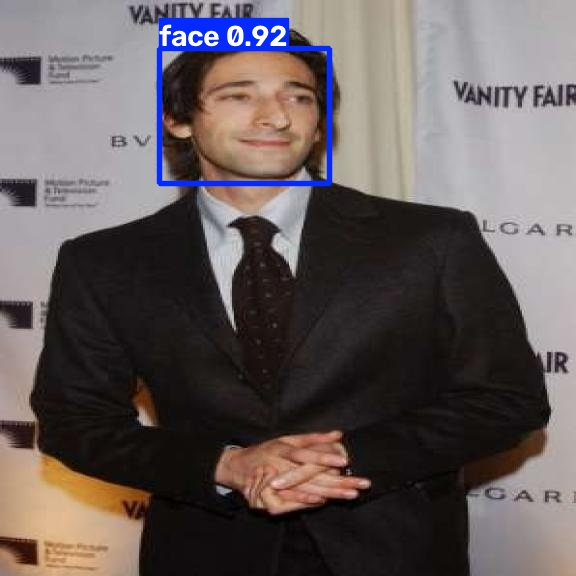

img_2029_jpg.rf.5aff632f4bb2b24ede52e9ecdbe8767a.jpg


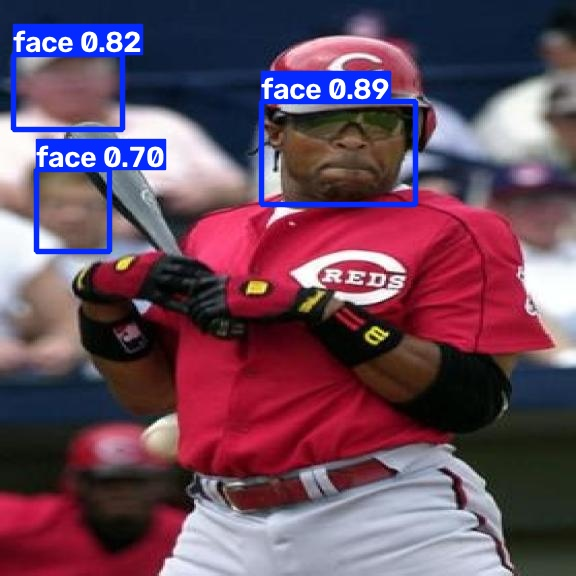

In [48]:
INFERENCE_IMAGES = test_images if test_images is not None else valid_images
detect_cmd = [sys.executable, "detect.py", "--weights", str(BEST_WEIGHTS),
              "--source", str(INFERENCE_IMAGES), "--img", str(IMAGE_SIZE),
              "--conf-thres", "0.25", "--project", "runs/detect",
              "--name", "face_predictions", "--exist-ok"]
subprocess.run(detect_cmd, cwd=str(YOLO_DIR), check=True)

prediction_dir = YOLO_DIR / "runs" / "detect" / "face_predictions"
predictions = [p for p in prediction_dir.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"}]
for image_path in predictions[:5]:
    print(image_path.name)
    display(Image.open(image_path))

## 10. Download the trained model

Download the `best.pt` checkpoint. You can also copy the entire training run to Google Drive for persistence between Colab sessions.

In [49]:
from google.colab import files
files.download(str(BEST_WEIGHTS))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Notes and troubleshooting

- **GitHub mode**: no Roboflow account or API key is required. Dataset files are cloned from the public repository.
- **Roboflow mode**: use the **YOLOv5 PyTorch** dataset format (`yolov5pytorch`). Make sure the dataset version is accessible to your API key.
- **Data paths**: the notebook builds an absolute-path YAML for Colab, independent of the relative paths supplied in the exported `data.yaml`.
- **Classes**: the supplied FaceDetector version has one class, `face`, but Roboflow exports from other projects may have different class definitions.
- **Session resets**: Colab storage under `/content` is ephemeral. Download weights or save them to Google Drive.
- **Compatibility**: YOLOv5 is distinct from newer Ultralytics YOLO versions. This notebook deliberately uses the official `ultralytics/yolov5` training scripts to follow the original YOLOv5 workflow.